##**Assignment** **10**

In [1]:
import pandas as pd

questions = {
    "risk_factors": [
        "What are the risk factors for heart disease?",
        "Does smoking increase heart disease risk?",
        "Does high cholesterol raise my heart risk?",
        "How does diabetes affect heart disease risk?",
        "Is high blood pressure a heart risk factor?",
        "Which habits raise the risk of heart disease?",
        "What increases my chances of heart disease?"
    ],
    "diet": [
        "Which foods are healthy for my heart?",
        "What should I include in a heart healthy diet?",
        "Which vegetables can I add to my meals?",
        "Should I reduce salt in my food?",
        "What are some healthy snack choices?",
        "How can I improve my eating habits?",
        "What foods should I limit in my diet?"
    ],
    "exercise": [
        "Which exercises are good for the heart?",
        "Is brisk walking good exercise?",
        "How much physical activity do adults need?",
        "Can cycling count as exercise?",
        "How often should adults exercise?",
        "How many minutes of walking should I aim for?",
        "What is an example of moderate physical activity?"
    ],
    "blood_pressure": [
        "Where can I check my blood pressure?",
        "Can I measure blood pressure at home?",
        "How do I find out if my blood pressure is high?",
        "Can a pharmacy check my blood pressure?",
        "Does high blood pressure usually have symptoms?",
        "Who can check my blood pressure?",
        "Should I monitor my blood pressure regularly?"
    ],
    "cholesterol": [
        "How is cholesterol measured?",
        "Which blood test checks cholesterol?",
        "Where can I get my cholesterol checked?",
        "How often should I get a cholesterol test?",
        "Who should I ask about cholesterol testing?",
        "Can a blood test show high cholesterol?",
        "How do I find out my cholesterol level?"
    ],
    "quit_smoking": [
        "How can I quit smoking?",
        "Who can help me stop smoking?",
        "Does quitting cigarettes help my heart?",
        "Where can I get help to quit tobacco?",
        "What is the benefit of quitting smoking?",
        "Can a doctor help me give up cigarettes?",
        "I want support to stop using tobacco"
    ]
}

rows = []
for intent, examples in questions.items():
    for query in examples:
        rows.append([query, intent])

df = pd.DataFrame(rows, columns=["query", "intent"])
print(df.groupby("intent").size())
print("Total queries:", len(df))

intent
blood_pressure    7
cholesterol       7
diet              7
exercise          7
quit_smoking      7
risk_factors      7
dtype: int64
Total queries: 42


In [2]:
taxonomy = {
    "Lifestyle": ["Diet", "Exercise"],
    "Screening": ["Blood pressure measurement", "Cholesterol testing"],
    "Risk factors": ["Medical conditions", "Tobacco use"],
    "Prevention support": ["Smoking cessation", "Clinical counselling"]
}

for category, subcategories in taxonomy.items():
    print(category, "->", ", ".join(subcategories))

relationships = [
    ("Smoking", "increases risk of", "Heart disease"),
    ("High blood pressure", "increases risk of", "Heart disease"),
    ("High cholesterol", "increases risk of", "Heart disease"),
    ("Diabetes", "increases risk of", "Heart disease"),
    ("Physical inactivity", "increases risk of", "Heart disease"),
    ("Brisk walking", "is a type of", "Physical activity"),
    ("Cycling", "is a type of", "Physical activity"),
    ("Physical activity", "can lower", "Blood pressure"),
    ("Reducing salt", "can lower", "Blood pressure"),
    ("Blood test", "can measure", "Cholesterol"),
    ("Quitting smoking", "reduces risk of", "Heart disease")
]

concepts = set()
for first, relation, second in relationships:
    concepts.update([first, second])

print("\nNumber of concepts:", len(concepts))
print("Number of relationships:", len(relationships))
display(pd.DataFrame(relationships, columns=["Concept 1", "Relationship", "Concept 2"]))

Lifestyle -> Diet, Exercise
Screening -> Blood pressure measurement, Cholesterol testing
Risk factors -> Medical conditions, Tobacco use
Prevention support -> Smoking cessation, Clinical counselling

Number of concepts: 14
Number of relationships: 11


,Concept 1,Relationship,Concept 2
0,Smoking,increases risk of,Heart disease
1,High blood pressure,increases risk of,Heart disease
2,High cholesterol,increases risk of,Heart disease
3,Diabetes,increases risk of,Heart disease
4,Physical inactivity,increases risk of,Heart disease
5,Brisk walking,is a type of,Physical activity
6,Cycling,is a type of,Physical activity
7,Physical activity,can lower,Blood pressure
8,Reducing salt,can lower,Blood pressure
9,Blood test,can measure,Cholesterol


In [3]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

stop_words = set(stopwords.words("english")) - {"no", "not", "nor"}
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    words = re.findall(r"[a-z]+", text.lower())
    clean_words = []
    for word in words:
        if word not in stop_words:
            clean_words.append(lemmatizer.lemmatize(word))
    return " ".join(clean_words)

print(preprocess("Which FOODS are healthy for my heart?"))

food healthy heart


Training questions: 30
Test questions: 12
Accuracy: 0.833
                precision    recall  f1-score   support

blood_pressure      0.667     1.000     0.800         2
   cholesterol      1.000     1.000     1.000         2
          diet      1.000     0.500     0.667         2
      exercise      0.667     1.000     0.800         2
  quit_smoking      1.000     1.000     1.000         2
  risk_factors      1.000     0.500     0.667         2

      accuracy                          0.833        12
     macro avg      0.889     0.833     0.822        12
  weighted avg      0.889     0.833     0.822        12



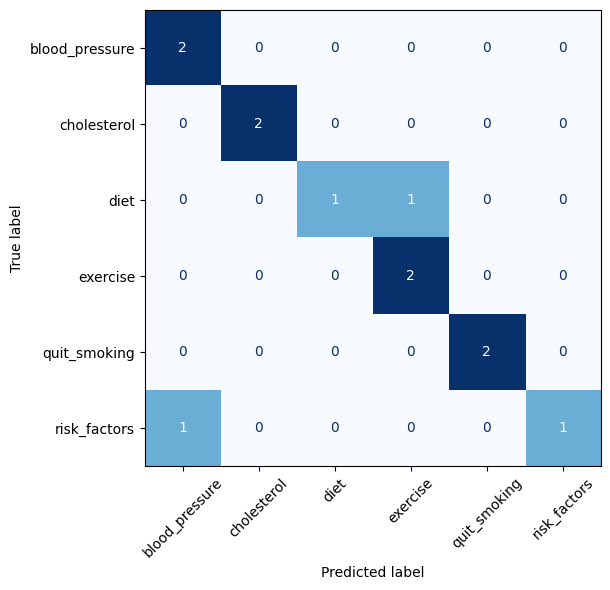

In [4]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

X_train, X_test, y_train, y_test = train_test_split(
    df["query"],
    df["intent"],
    test_size=12,
    stratify=df["intent"],
    random_state=42
)

model = make_pipeline(
    TfidfVectorizer(preprocessor=preprocess, ngram_range=(1, 2)),
    LogisticRegression(C=8, max_iter=1000)
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Training questions:", len(X_train))
print("Test questions:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print(classification_report(y_test, predictions, digits=3, zero_division=0))

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False
)
plt.tight_layout()
plt.show()

In [5]:
answers = {
    "risk_factors": "Smoking, high blood pressure, high cholesterol and diabetes can increase the risk of heart disease.",
    "diet": "Choose fruits, vegetables and foods rich in fibre. Limit salty processed foods and foods high in saturated fat.",
    "exercise": "For adults, a general goal is 150 minutes of moderate activity per week. Brisk walking and cycling are examples.",
    "blood_pressure": "High blood pressure often has no symptoms. You can have it measured at a clinic, at a pharmacy or with a home monitor. Ask your clinician how often to check.",
    "cholesterol": "A blood test measures cholesterol. Ask your healthcare team when to get tested, since the interval depends on your history and risk factors.",
    "quit_smoking": "Quitting smoking lowers heart disease risk. A healthcare professional can help you choose a way to quit and find support."
}

In [7]:
vectorizer = model.named_steps["tfidfvectorizer"]

def assistant(query):
    text = " ".join(query.lower().replace("’", "'").split())

    emergency = r"\b(chest (pain|pressure|tightness)|crushing chest|can't breathe|cannot breathe|severe shortness of breath|having a heart attack)\b"
    if re.search(emergency, text):
        return "emergency", "If this is happening now, call 112 in India or your local emergency number immediately."

    if not text:
        return "empty", "Please enter a heart health question."

    if text.strip("!?.") in {"hello", "hi", "hey"}:
        return "greeting", "Hello! What would you like to know about heart health?"

    if re.search(r"\b(dose|dosage|how many tablets|stop my medicine|double my medication)\b", text):
        return "medication", "Please ask your doctor or pharmacist about your medicine or dose."

    if re.search(r"\b(rash|toothache|acne|earache|dandruff)\b", text):
        return "unsupported", "That topic is outside the heart health topics I cover."

    features = vectorizer.transform([text])
    if features.nnz == 0:
        return "low_confidence", "Could you explain what you want to know about heart health?"

    probabilities = model.predict_proba([text])[0]
    best = probabilities.argmax()

    if probabilities[best] < 0.35:
        return "low_confidence", "Could you be more specific? For example, are you asking about diet, exercise or a health check?"

    intent = model.classes_[best]
    return intent, answers[intent]

In [8]:
tests = [
    ("Which factors increase heart disease risk?", "risk_factors"),
    ("What foods belong in a healthy diet?", "diet"),
    ("Is brisk walking a moderate physical activity?", "exercise"),
    ("Can I check blood pressure at a pharmacy?", "blood_pressure"),
    ("Can I get a blood test for cholesterol?", "cholesterol"),
    ("Where can I get support to quit smoking?", "quit_smoking"),
    ("Could cycling be part of my weekly exercise routine?", "exercise"),
    ("What should I apply to a skin rash?", "unsupported"),
    ("Could you explain that again?", "low_confidence"),
    ("I have chest pain and cannot breathe", "emergency")
]

results = []
for query, expected in tests:
    predicted, reply = assistant(query)
    results.append([query, expected, predicted, expected == predicted, reply])

pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(results, columns=["Query", "Expected", "Predicted", "Match", "Reply"]))

,Query,Expected,Predicted,Match,Reply
0,Which factors increase heart disease risk?,risk_factors,risk_factors,True,"Smoking, high blood pressure, high cholesterol and diabetes can increase the risk of heart disease."
1,What foods belong in a healthy diet?,diet,diet,True,"Choose fruits, vegetables and foods rich in fibre. Limit salty processed foods and foods high in saturated fat."
2,Is brisk walking a moderate physical activity?,exercise,exercise,True,"For adults, a general goal is 150 minutes of moderate activity per week. Brisk walking and cycling are examples."
3,Can I check blood pressure at a pharmacy?,blood_pressure,blood_pressure,True,"High blood pressure often has no symptoms. You can have it measured at a clinic, at a pharmacy or with a home monitor. Ask your clinician how often to check."
4,Can I get a blood test for cholesterol?,cholesterol,cholesterol,True,"A blood test measures cholesterol. Ask your healthcare team when to get tested, since the interval depends on your history and risk factors."
5,Where can I get support to quit smoking?,quit_smoking,quit_smoking,True,Quitting smoking lowers heart disease risk. A healthcare professional can help you choose a way to quit and find support.
6,Could cycling be part of my weekly exercise routine?,exercise,exercise,True,"For adults, a general goal is 150 minutes of moderate activity per week. Brisk walking and cycling are examples."
7,What should I apply to a skin rash?,unsupported,unsupported,True,That topic is outside the heart health topics I cover.
8,Could you explain that again?,low_confidence,low_confidence,True,Could you explain what you want to know about heart health?
9,I have chest pain and cannot breathe,emergency,emergency,True,"If this is happening now, call 112 in India or your local emergency number immediately."


In [11]:
print("Heart Health Information Assistant")
print("Ask a heart health question or type exit to finish.")

while True:
    query = input("You: ")
    if query.strip().lower() == "exit":
        print("Assistant: Goodbye!")
        break

    intent, reply = assistant(query)
    print("Intent:", intent)
    print("Assistant:", reply)
    print()

Heart Health Information Assistant
Ask a heart health question or type exit to finish.
You: Can I check my blood pressure at a pharmacy?
Intent: blood_pressure
Assistant: High blood pressure often has no symptoms. You can have it measured at a clinic, at a pharmacy or with a home monitor. Ask your clinician how often to check.

You: exit
Assistant: Goodbye!
